# MINDSYNC AI: DIGITAL WELLBEING AND ATTENTION COACH

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix,precision_score,recall_score,f1_score
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"D:\Imarticus\ML\teen_phone_addiction_dataset.csv")
df

,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,...,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level
0,1,Shannon Francis,13,Female,Hansonfort,9th,4.0,6.1,78,5,...,1.4,86,19,3.6,1.7,1.2,Browsing,4,8.7,10.0
1,2,Scott Rodriguez,17,Female,Theodorefort,7th,5.5,6.5,70,5,...,0.9,96,9,1.1,4.0,1.8,Browsing,2,5.3,10.0
2,3,Adrian Knox,13,Other,Lindseystad,11th,5.8,5.5,93,8,...,0.5,137,8,0.3,1.5,0.4,Education,6,5.7,9.2
3,4,Brittany Hamilton,18,Female,West Anthony,12th,3.1,3.9,78,8,...,1.4,128,7,3.1,1.6,0.8,Social Media,8,3.0,9.8
4,5,Steven Smith,14,Other,Port Lindsaystad,9th,2.5,6.7,56,4,...,1.0,96,20,2.6,0.9,1.1,Gaming,10,3.7,8.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2996,Jesus Yates,16,Female,New Jennifer,12th,3.9,6.4,53,4,...,0.3,80,15,2.7,1.8,1.0,Other,8,9.4,9.8
2996,2997,Bethany Murray,13,Female,Richardport,8th,3.6,7.3,93,5,...,0.9,45,8,3.1,0.0,0.3,Gaming,9,5.2,5.5
2997,2998,Norman Hughes,14,Other,Rebeccaton,7th,3.2,6.5,98,1,...,0.2,51,13,2.4,0.2,2.4,Social Media,9,5.9,6.2
2998,2999,Barbara Hinton,17,Female,Ramirezmouth,9th,6.7,7.5,67,3,...,1.6,125,17,1.7,2.6,1.5,Browsing,4,6.1,10.0


In [3]:
df.head()

,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,...,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level
0,1,Shannon Francis,13,Female,Hansonfort,9th,4.0,6.1,78,5,...,1.4,86,19,3.6,1.7,1.2,Browsing,4,8.7,10.0
1,2,Scott Rodriguez,17,Female,Theodorefort,7th,5.5,6.5,70,5,...,0.9,96,9,1.1,4.0,1.8,Browsing,2,5.3,10.0
2,3,Adrian Knox,13,Other,Lindseystad,11th,5.8,5.5,93,8,...,0.5,137,8,0.3,1.5,0.4,Education,6,5.7,9.2
3,4,Brittany Hamilton,18,Female,West Anthony,12th,3.1,3.9,78,8,...,1.4,128,7,3.1,1.6,0.8,Social Media,8,3.0,9.8
4,5,Steven Smith,14,Other,Port Lindsaystad,9th,2.5,6.7,56,4,...,1.0,96,20,2.6,0.9,1.1,Gaming,10,3.7,8.6


In [4]:
df.tail()

,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,...,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level
2995,2996,Jesus Yates,16,Female,New Jennifer,12th,3.9,6.4,53,4,...,0.3,80,15,2.7,1.8,1.0,Other,8,9.4,9.8
2996,2997,Bethany Murray,13,Female,Richardport,8th,3.6,7.3,93,5,...,0.9,45,8,3.1,0.0,0.3,Gaming,9,5.2,5.5
2997,2998,Norman Hughes,14,Other,Rebeccaton,7th,3.2,6.5,98,1,...,0.2,51,13,2.4,0.2,2.4,Social Media,9,5.9,6.2
2998,2999,Barbara Hinton,17,Female,Ramirezmouth,9th,6.7,7.5,67,3,...,1.6,125,17,1.7,2.6,1.5,Browsing,4,6.1,10.0
2999,3000,Curtis Johnson,17,Male,Lake Alexander,10th,3.5,6.9,79,4,...,0.6,117,8,0.0,2.3,0.1,Education,7,5.1,6.3


In [5]:
df.shape

(3000, 25)

In [6]:
df.sample()

,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,...,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level
2738,2739,Steven Prince,18,Other,North Jordan,12th,2.5,3.4,55,9,...,0.5,125,5,1.5,1.2,1.7,Social Media,7,4.8,7.0


In [7]:
df.dtypes

ID                          int64
Name                       object
Age                         int64
Gender                     object
Location                   object
School_Grade               object
Daily_Usage_Hours         float64
Sleep_Hours               float64
Academic_Performance        int64
Social_Interactions         int64
Exercise_Hours            float64
Anxiety_Level               int64
Depression_Level            int64
Self_Esteem                 int64
Parental_Control            int64
Screen_Time_Before_Bed    float64
Phone_Checks_Per_Day        int64
Apps_Used_Daily             int64
Time_on_Social_Media      float64
Time_on_Gaming            float64
Time_on_Education         float64
Phone_Usage_Purpose        object
Family_Communication        int64
Weekend_Usage_Hours       float64
Addiction_Level           float64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      3000 non-null   int64  
 1   Name                    3000 non-null   object 
 2   Age                     3000 non-null   int64  
 3   Gender                  3000 non-null   object 
 4   Location                3000 non-null   object 
 5   School_Grade            3000 non-null   object 
 6   Daily_Usage_Hours       3000 non-null   float64
 7   Sleep_Hours             3000 non-null   float64
 8   Academic_Performance    3000 non-null   int64  
 9   Social_Interactions     3000 non-null   int64  
 10  Exercise_Hours          3000 non-null   float64
 11  Anxiety_Level           3000 non-null   int64  
 12  Depression_Level        3000 non-null   int64  
 13  Self_Esteem             3000 non-null   int64  
 14  Parental_Control        3000 non-null   

In [9]:
df.describe()

,ID,Age,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,Exercise_Hours,Anxiety_Level,Depression_Level,Self_Esteem,Parental_Control,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Family_Communication,Weekend_Usage_Hours,Addiction_Level
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1500.500000,15.969667,5.020667,6.489767,74.947333,5.097667,1.040667,5.590000,5.460333,5.546333,0.507333,1.006733,83.093000,12.609333,2.499233,1.525267,1.016333,5.459667,6.015100,8.881900
std,866.169729,1.989489,1.956501,1.490713,14.684156,3.139333,0.734620,2.890678,2.871557,2.860754,0.500030,0.492878,37.747044,4.611486,0.988201,0.932701,0.648341,2.864572,2.014776,1.609598
min,1.000000,13.000000,0.000000,3.000000,50.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,20.000000,5.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
25%,750.750000,14.000000,3.700000,5.500000,62.000000,2.000000,0.500000,3.000000,3.000000,3.000000,0.000000,0.700000,51.000000,9.000000,1.800000,0.800000,0.500000,3.000000,4.700000,8.000000
50%,1500.500000,16.000000,5.000000,6.500000,75.000000,5.000000,1.000000,6.000000,5.000000,6.000000,1.000000,1.000000,82.000000,13.000000,2.500000,1.500000,1.000000,5.000000,6.000000,10.000000
75%,2250.250000,18.000000,6.400000,7.500000,88.000000,8.000000,1.500000,8.000000,8.000000,8.000000,1.000000,1.400000,115.250000,17.000000,3.200000,2.200000,1.500000,8.000000,7.400000,10.000000
max,3000.000000,19.000000,11.500000,10.000000,100.000000,10.000000,4.000000,10.000000,10.000000,10.000000,1.000000,2.600000,150.000000,20.000000,5.000000,4.000000,3.000000,10.000000,14.000000,10.000000


In [10]:
df.columns

Index(['ID', 'Name', 'Age', 'Gender', 'Location', 'School_Grade',
       'Daily_Usage_Hours', 'Sleep_Hours', 'Academic_Performance',
       'Social_Interactions', 'Exercise_Hours', 'Anxiety_Level',
       'Depression_Level', 'Self_Esteem', 'Parental_Control',
       'Screen_Time_Before_Bed', 'Phone_Checks_Per_Day', 'Apps_Used_Daily',
       'Time_on_Social_Media', 'Time_on_Gaming', 'Time_on_Education',
       'Phone_Usage_Purpose', 'Family_Communication', 'Weekend_Usage_Hours',
       'Addiction_Level'],
      dtype='object')

In [11]:
df.isnull().sum()

ID                        0
Name                      0
Age                       0
Gender                    0
Location                  0
School_Grade              0
Daily_Usage_Hours         0
Sleep_Hours               0
Academic_Performance      0
Social_Interactions       0
Exercise_Hours            0
Anxiety_Level             0
Depression_Level          0
Self_Esteem               0
Parental_Control          0
Screen_Time_Before_Bed    0
Phone_Checks_Per_Day      0
Apps_Used_Daily           0
Time_on_Social_Media      0
Time_on_Gaming            0
Time_on_Education         0
Phone_Usage_Purpose       0
Family_Communication      0
Weekend_Usage_Hours       0
Addiction_Level           0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df = df.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

In [14]:
print(df["Addiction_Level"].describe())

print(df["Addiction_Level"].value_counts().sort_index())

count    3000.000000
mean        8.881900
std         1.609598
min         1.000000
25%         8.000000
50%        10.000000
75%        10.000000
max        10.000000
Name: Addiction_Level, dtype: float64
Addiction_Level
1.0        1
1.4        2
2.0        1
2.1        2
2.2        1
        ... 
9.6       46
9.7       37
9.8       28
9.9       50
10.0    1524
Name: count, Length: 80, dtype: int64


In [15]:
df = df[
    df["Addiction_Level"].between(0, 10)
].copy()

df["Risk_Level"] = pd.cut(
    df["Addiction_Level"],
    bins=[-0.001, 3.33, 6.67, 10],
    labels=["Low", "Medium", "High"],
    include_lowest=True,
    right=False
)

# The final bin needs to include the maximum score of 10.
# Set the upper boundary above 10 for reliable inclusion.
df["Risk_Level"] = pd.cut(
    df["Addiction_Level"],
    bins=[-0.001, 3.33, 6.67, 10.001],
    labels=["Low", "Medium", "High"],
    include_lowest=True,
    right=False
)

display(df["Risk_Level"].value_counts())

Risk_Level
High      2647
Medium     331
Low         22
Name: count, dtype: int64

### Check how many people belong to each class

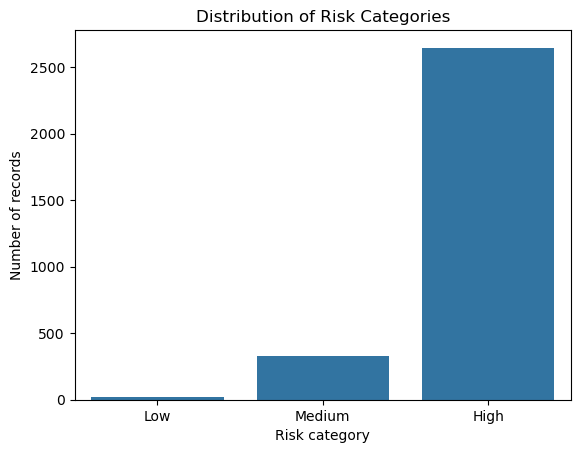

In [16]:
sns.countplot(
    data=df,
    x="Risk_Level",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Risk Categories")
plt.xlabel("Risk category")
plt.ylabel("Number of records")
plt.show()

### Compare usage with the target

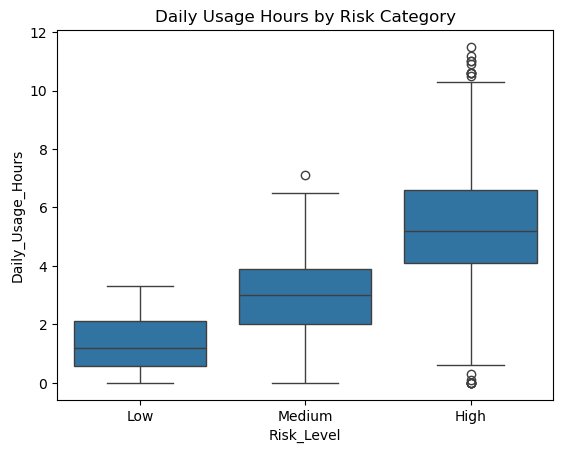

In [17]:
sns.boxplot(
    data=df,
    x="Risk_Level",
    y="Daily_Usage_Hours",
    order=["Low", "Medium", "High"]
)

plt.title("Daily Usage Hours by Risk Category")
plt.show()

### Explore phone checking

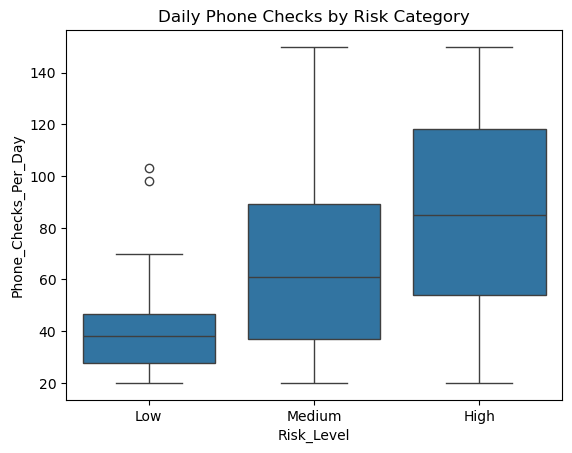

In [18]:
sns.boxplot(
    data=df,
    x="Risk_Level",
    y="Phone_Checks_Per_Day",
    order=["Low", "Medium", "High"]
)

plt.title("Daily Phone Checks by Risk Category")
plt.show()

### Explore sleep

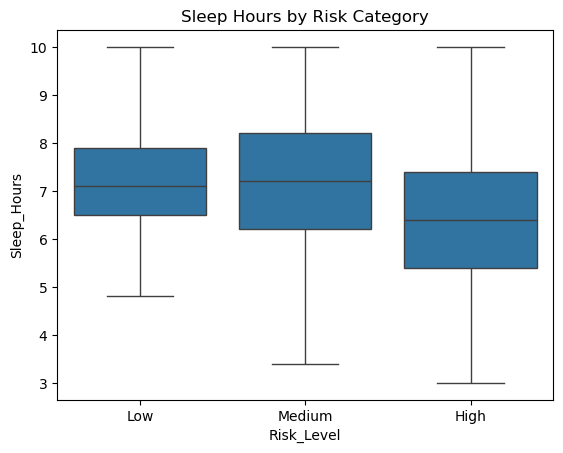

In [19]:
sns.boxplot(
    data=df,
    x="Risk_Level",
    y="Sleep_Hours",
    order=["Low", "Medium", "High"]
)

plt.title("Sleep Hours by Risk Category")
plt.show()

### Explore relationships between numerical features

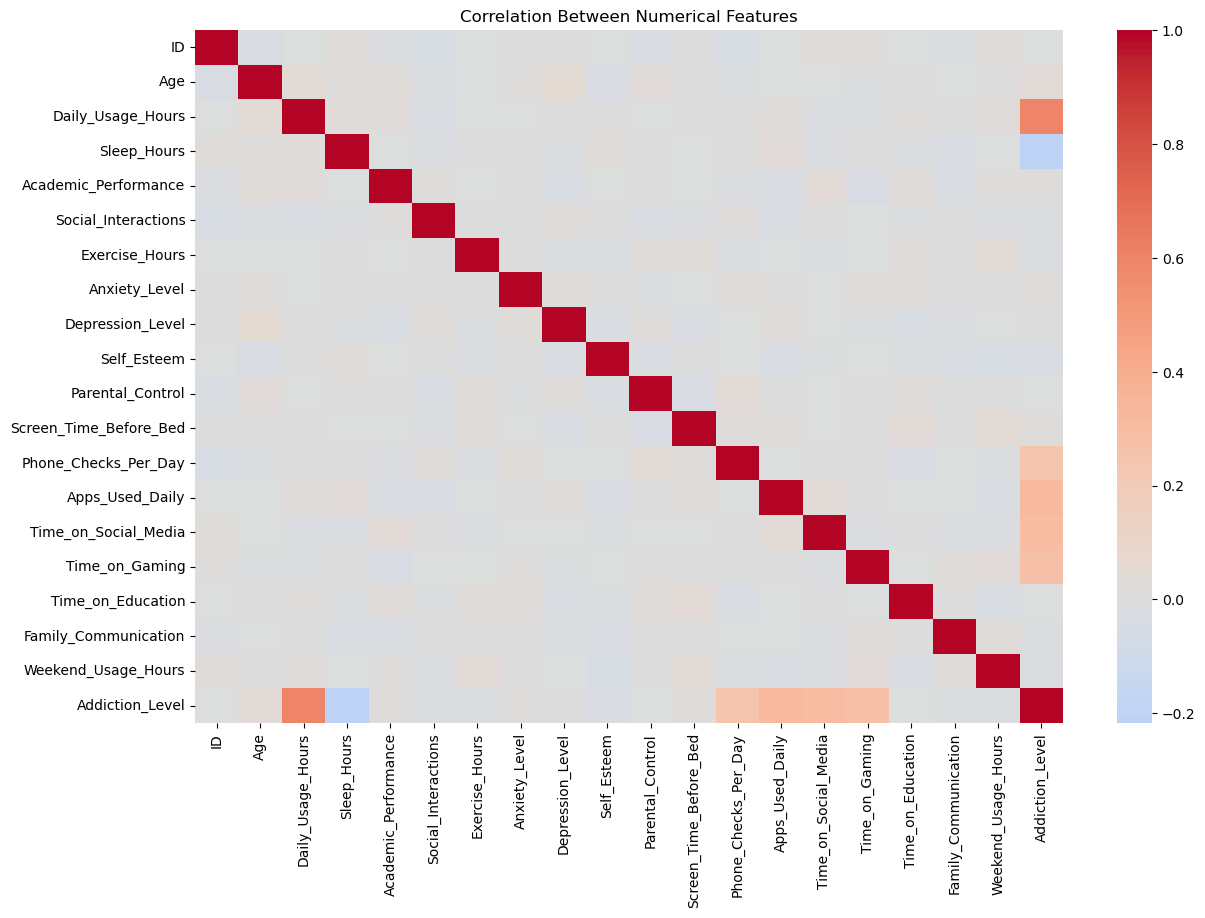

In [20]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(14, 9))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Features")
plt.show()

In [21]:
from sklearn.preprocessing import LabelEncoder

df = df.copy()

# Convert text columns into numeric values
le = LabelEncoder()

for col in df.select_dtypes(include="object").columns:
    df[col] = le.fit_transform(df[col].astype(str))

In [22]:
print(df.columns.tolist())

['ID', 'Name', 'Age', 'Gender', 'Location', 'School_Grade', 'Daily_Usage_Hours', 'Sleep_Hours', 'Academic_Performance', 'Social_Interactions', 'Exercise_Hours', 'Anxiety_Level', 'Depression_Level', 'Self_Esteem', 'Parental_Control', 'Screen_Time_Before_Bed', 'Phone_Checks_Per_Day', 'Apps_Used_Daily', 'Time_on_Social_Media', 'Time_on_Gaming', 'Time_on_Education', 'Phone_Usage_Purpose', 'Family_Communication', 'Weekend_Usage_Hours', 'Addiction_Level', 'Risk_Level']


In [23]:
target = "Risk_Level"

drop_columns = [
    "ID",
    "Name",
    "Location",
    "School_Grade",
    "Addiction_Level"
]

X = df.drop(
    columns=drop_columns + [target],
    errors="ignore"
)

y = df[target]

print("Features:", X.shape)
print("Target:", y.shape)

display(X.head())

Features: (3000, 20)
Target: (3000,)


,Age,Gender,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,Exercise_Hours,Anxiety_Level,Depression_Level,Self_Esteem,Parental_Control,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours
0,13,0,4.0,6.1,78,5,0.1,10,3,8,0,1.4,86,19,3.6,1.7,1.2,0,4,8.7
1,17,0,5.5,6.5,70,5,0.0,3,7,3,0,0.9,96,9,1.1,4.0,1.8,0,2,5.3
2,13,2,5.8,5.5,93,8,0.8,2,3,10,0,0.5,137,8,0.3,1.5,0.4,1,6,5.7
3,18,0,3.1,3.9,78,8,1.6,9,10,3,0,1.4,128,7,3.1,1.6,0.8,4,8,3.0
4,14,2,2.5,6.7,56,4,1.1,1,5,1,0,1.0,96,20,2.6,0.9,1.1,2,10,3.7


In [24]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3000, 20)
y shape: (3000,)


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 2400
Testing records: 600


In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
lor = LogisticRegression()

In [28]:
lor.fit(X_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [29]:
y_pred_lor = lor.predict(X_test_scaled)

In [30]:
print("Accuracy Score",accuracy_score(y_pred_lor,y_test))

Accuracy Score 0.9916666666666667


In [31]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lor, zero_division=0))


Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00       530
         Low       1.00      0.50      0.67         4
      Medium       0.94      0.98      0.96        66

    accuracy                           0.99       600
   macro avg       0.98      0.83      0.88       600
weighted avg       0.99      0.99      0.99       600



In [32]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lor))


Confusion Matrix:
[[528   0   2]
 [  0   2   2]
 [  1   0  65]]


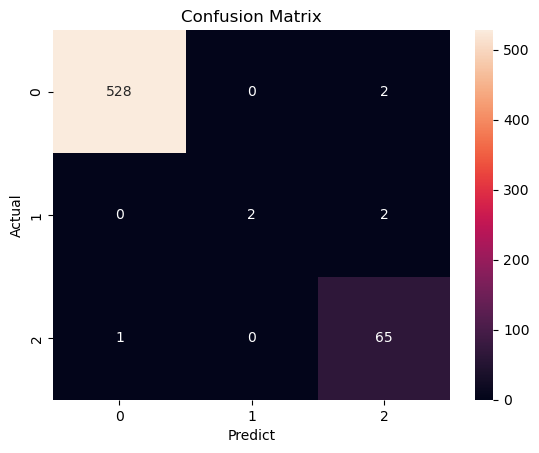

In [33]:
cm = confusion_matrix(y_test,y_pred_lor)
sns.heatmap(cm , annot = True , fmt = 'd')
plt.xlabel('Predict')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [34]:
rf = RandomForestClassifier()

In [35]:
rf.fit(X_train_scaled,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [36]:
y_pred_rf = rf.predict(X_test_scaled)

In [37]:
print("Accuracy Score",accuracy_score(y_pred_lor,y_test))

Accuracy Score 0.9916666666666667


In [38]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lor, zero_division=0))


Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00       530
         Low       1.00      0.50      0.67         4
      Medium       0.94      0.98      0.96        66

    accuracy                           0.99       600
   macro avg       0.98      0.83      0.88       600
weighted avg       0.99      0.99      0.99       600



In [39]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lor))


Confusion Matrix:
[[528   0   2]
 [  0   2   2]
 [  1   0  65]]


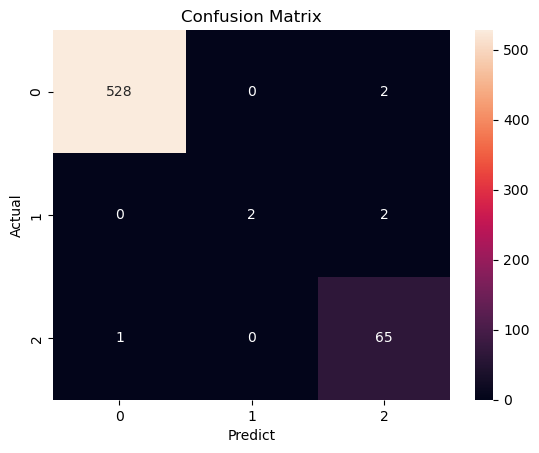

In [40]:
cm = confusion_matrix(y_test,y_pred_lor)
sns.heatmap(cm , annot = True , fmt = 'd')
plt.xlabel('Predict')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [41]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

In [42]:
xgb_model = XGBClassifier()

In [43]:
xgb_model.fit(X_train_scaled, y_train_encoded)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [44]:
y_pred = xgb_model.predict(X_test_scaled)

In [45]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test_encoded, y_pred))
print(classification_report(
    y_test_encoded,
    y_pred,
    target_names=le.classes_
))

Accuracy: 0.9433333333333334
              precision    recall  f1-score   support

        High       0.96      0.98      0.97       530
         Low       1.00      0.25      0.40         4
      Medium       0.76      0.71      0.73        66

    accuracy                           0.94       600
   macro avg       0.91      0.65      0.70       600
weighted avg       0.94      0.94      0.94       600



In [46]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred))


Confusion Matrix:
[[518   0  12]
 [  0   1   3]
 [ 19   0  47]]


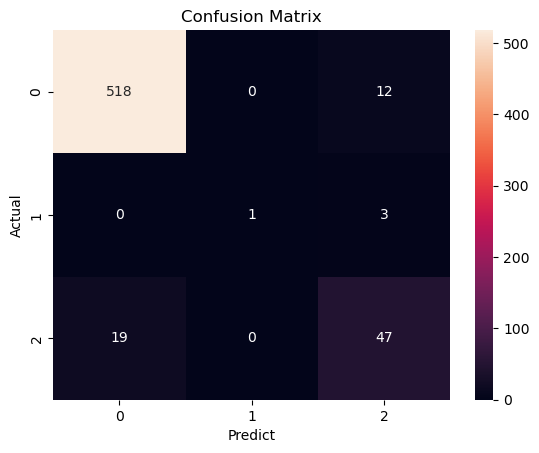

In [47]:
cm = confusion_matrix(y_test_encoded, y_pred)
sns.heatmap(cm , annot = True , fmt = 'd')
plt.xlabel('Predict')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Logistic Regression": y_pred_lor,
    "Random Forest": y_pred_rf,
    # "XGBoost": y_pred
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions,
            average="weighted", zero_division=0
        )
    })

comparison = pd.DataFrame(results)
print(comparison.round(2))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression      0.99       0.99    0.99      0.99
1        Random Forest      0.90       0.88    0.90      0.87


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lor),
        "Precision": precision_score(y_test, y_pred_lor, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred_lor, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_lor, average="weighted", zero_division=0)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Precision": precision_score(y_test, y_pred_rf, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred_rf, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_rf, average="weighted", zero_division=0)
    },
    {
        "Model": "XGBoost",
        "Accuracy": accuracy_score(y_test_encoded, y_pred),
        "Precision": precision_score(y_test_encoded, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test_encoded, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test_encoded, y_pred, average="weighted", zero_division=0)
    }
])

print(comparison.round(2))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression      0.99       0.99    0.99      0.99
1        Random Forest      0.90       0.88    0.90      0.87
2              XGBoost      0.94       0.94    0.94      0.94


In [50]:
# 1. Check target distribution
print("Target distribution:")
print(y.value_counts())

# 2. Check whether the predictions exactly match the true labels
print("\nLogistic Regression errors:",
      (y_test.to_numpy() != y_pred).sum())

print("Random Forest errors:",
      (y_test.to_numpy() != y_pred_rf).sum())

print("XGBoost errors:",
      (y_test.to_numpy() != y_pred).sum())


Target distribution:
Risk_Level
High      2647
Medium     331
Low         22
Name: count, dtype: int64

Logistic Regression errors: 600
Random Forest errors: 58
XGBoost errors: 600


                   Feature  Importance
2        Daily_Usage_Hours    0.254401
14    Time_on_Social_Media    0.094229
15          Time_on_Gaming    0.091539
13         Apps_Used_Daily    0.076299
12    Phone_Checks_Per_Day    0.071444
3              Sleep_Hours    0.069651
19     Weekend_Usage_Hours    0.037392
4     Academic_Performance    0.034898
6           Exercise_Hours    0.033255
16       Time_on_Education    0.032322
11  Screen_Time_Before_Bed    0.029366
8         Depression_Level    0.025144
5      Social_Interactions    0.025105
9              Self_Esteem    0.024653
7            Anxiety_Level    0.023548
18    Family_Communication    0.023540
0                      Age    0.018929
17     Phone_Usage_Purpose    0.016335
1                   Gender    0.011871
10        Parental_Control    0.006079


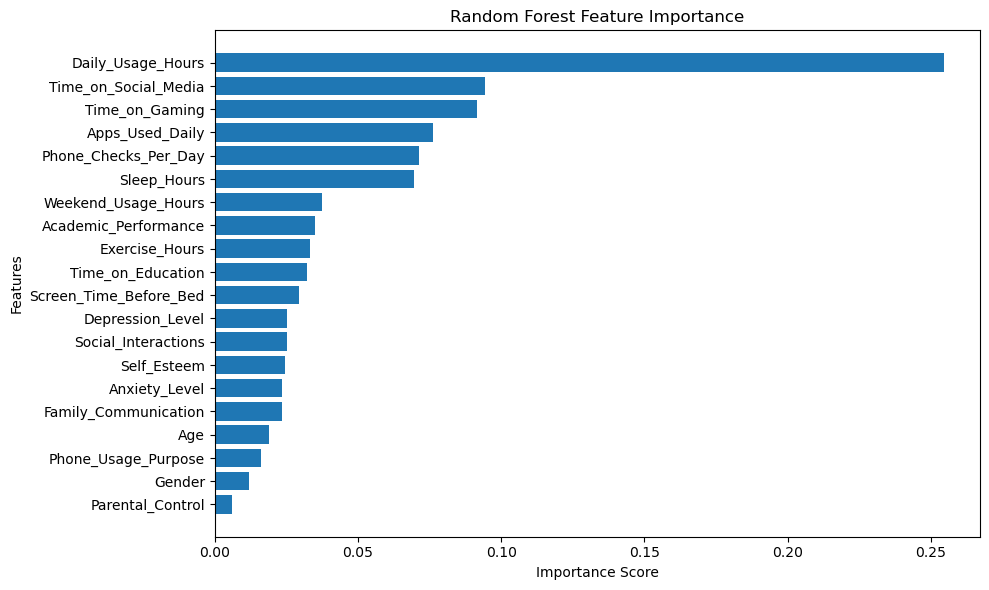

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print(feature_importance)

plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [52]:
def usage_rules(data):
    rules = []

    if data["Daily_Screen_Time"] >= 6:
        rules.append("High daily screen time")

    if data["Notifications_Per_Day"] >= 100:
        rules.append("Frequent notifications")

    if data["Reels_Per_Day"] >= 100:
        rules.append("High short-video consumption")

    if data["Night_Usage"] == 1:
        rules.append("Social media use at night")

    if data["Scrolling_Sessions"] >= 20:
        rules.append("Frequent scrolling sessions")

    if not rules:
        rules.append("No high-usage patterns detected by these rules")

    return rules

In [53]:
import joblib

joblib.dump(rf, "information_overload_model.pkl")

['information_overload_model.pkl']

In [54]:
import streamlit as st

print("Streamlit version:", st.__version__)

Streamlit version: 1.51.0


In [55]:
import os
print(os.getcwd())

C:\Users\SM\capstone project


In [56]:
import os

print("Notebook save location:")
print(os.getcwd())

print("\nModel folder contents:")
# print(os.listdir("returnshield_models"))

Notebook save location:
C:\Users\SM\capstone project

Model folder contents:


In [57]:
print(df.columns.tolist())

['ID', 'Name', 'Age', 'Gender', 'Location', 'School_Grade', 'Daily_Usage_Hours', 'Sleep_Hours', 'Academic_Performance', 'Social_Interactions', 'Exercise_Hours', 'Anxiety_Level', 'Depression_Level', 'Self_Esteem', 'Parental_Control', 'Screen_Time_Before_Bed', 'Phone_Checks_Per_Day', 'Apps_Used_Daily', 'Time_on_Social_Media', 'Time_on_Gaming', 'Time_on_Education', 'Phone_Usage_Purpose', 'Family_Communication', 'Weekend_Usage_Hours', 'Addiction_Level', 'Risk_Level']


In [58]:
print(type(rf))
print(type(scaler))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>
<class 'sklearn.preprocessing._data.StandardScaler'>


In [59]:

print("Model:", type(rf).__name__)
print("Scaler:", type(scaler).__name__)

print("\nNumber of model features:", rf.n_features_in_)
print("Number of scaler features:", scaler.n_features_in_)

print("\nExact feature names and order:")
print(X_train.columns.tolist())

print("\nPrediction classes:")
print(rf.classes_)


Model: RandomForestClassifier
Scaler: StandardScaler

Number of model features: 20
Number of scaler features: 20

Exact feature names and order:
['Age', 'Gender', 'Daily_Usage_Hours', 'Sleep_Hours', 'Academic_Performance', 'Social_Interactions', 'Exercise_Hours', 'Anxiety_Level', 'Depression_Level', 'Self_Esteem', 'Parental_Control', 'Screen_Time_Before_Bed', 'Phone_Checks_Per_Day', 'Apps_Used_Daily', 'Time_on_Social_Media', 'Time_on_Gaming', 'Time_on_Education', 'Phone_Usage_Purpose', 'Family_Communication', 'Weekend_Usage_Hours']

Prediction classes:
['High' 'Low' 'Medium']


In [60]:

import joblib
from pathlib import Path

MODEL_FOLDER = Path("mindsync_models")
MODEL_FOLDER.mkdir(exist_ok=True)

bundle = {
    "model": rf,
    "scaler": scaler,
    "features": X_train.columns.tolist(),
    "classes": rf.classes_.tolist()
}

joblib.dump(
    bundle,
    MODEL_FOLDER / "mindsync_model_bundle.joblib"
)

print("Existing model backup saved successfully.")
print("Location:", MODEL_FOLDER.resolve())


Existing model backup saved successfully.
Location: C:\Users\SM\capstone project\mindsync_models


In [61]:

import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Reload the original, unencoded dataset
raw_df = pd.read_csv(
    r"D:\Imarticus\ML\teen_phone_addiction_dataset.csv"
)

# Recover the exact mappings for the categorical input columns
for col in ["Gender", "Phone_Usage_Purpose"]:
    print(f"\n{col} mapping:")

    encoder = LabelEncoder()
    encoder.fit(raw_df[col].astype(str))

    for code, category in enumerate(encoder.classes_):
        print(f"{category} -> {code}")



Gender mapping:
Female -> 0
Male -> 1
Other -> 2

Phone_Usage_Purpose mapping:
Browsing -> 0
Education -> 1
Gaming -> 2
Other -> 3
Social Media -> 4


In [62]:

import joblib
from pathlib import Path

MODEL_FOLDER = Path("mindsync_models")
MODEL_FOLDER.mkdir(exist_ok=True)

bundle = {
    "model": rf,
    "scaler": scaler,
    "features": X_train.columns.tolist(),
    "classes": rf.classes_.tolist(),

    "categories": {
        "Gender": {
            "Female": 0,
            "Male": 1,
            "Other": 2
        },
        "Phone_Usage_Purpose": {
            "Browsing": 0,
            "Education": 1,
            "Gaming": 2,
            "Other": 3,
            "Social Media": 4
        }
    }
}

model_path = MODEL_FOLDER / "mindsync_model_bundle.joblib"

joblib.dump(bundle, model_path)

print("MindSync AI model bundle saved!")
print("Path:", model_path.resolve())
print("Features:", len(bundle["features"]))
print("Classes:", bundle["classes"])


MindSync AI model bundle saved!
Path: C:\Users\SM\capstone project\mindsync_models\mindsync_model_bundle.joblib
Features: 20
Classes: ['High', 'Low', 'Medium']


In [63]:

saved_bundle = joblib.load(
    "mindsync_models/mindsync_model_bundle.joblib"
)

# Use one existing training row to test the saved model
sample = X_train.iloc[[0]][saved_bundle["features"]]
sample_scaled = saved_bundle["scaler"].transform(sample)

original_prediction = rf.predict(sample_scaled)[0]
saved_prediction = saved_bundle["model"].predict(sample_scaled)[0]

print("Original model prediction:", original_prediction)
print("Saved model prediction:", saved_prediction)

assert original_prediction == saved_prediction

print("SUCCESS: Saved model matches the original model.")


Original model prediction: High
Saved model prediction: High
SUCCESS: Saved model matches the original model.


In [64]:

# Verify the saved model bundle and feature order

print("Number of model features:", len(saved_bundle["features"]))
print("\nExact training feature order:")

for i, feature in enumerate(saved_bundle["features"], start=1):
    print(f"{i}. {feature}")

print("\nScaler feature count:", saved_bundle["scaler"].n_features_in_)
print("Model class order:", saved_bundle["classes"])

# Check whether the scaler remembers the original column names
if hasattr(saved_bundle["scaler"], "feature_names_in_"):
    print("\nScaler feature order:")
    print(list(saved_bundle["scaler"].feature_names_in_))

# Check category mappings
print("\nCategory mappings:")
print(saved_bundle["categories"])

assert len(saved_bundle["features"]) == 20
assert saved_bundle["scaler"].n_features_in_ == 20

print("\nSUCCESS: Bundle contains 20 features.")


Number of model features: 20

Exact training feature order:
1. Age
2. Gender
3. Daily_Usage_Hours
4. Sleep_Hours
5. Academic_Performance
6. Social_Interactions
7. Exercise_Hours
8. Anxiety_Level
9. Depression_Level
10. Self_Esteem
11. Parental_Control
12. Screen_Time_Before_Bed
13. Phone_Checks_Per_Day
14. Apps_Used_Daily
15. Time_on_Social_Media
16. Time_on_Gaming
17. Time_on_Education
18. Phone_Usage_Purpose
19. Family_Communication
20. Weekend_Usage_Hours

Scaler feature count: 20
Model class order: ['High', 'Low', 'Medium']

Scaler feature order:
['Age', 'Gender', 'Daily_Usage_Hours', 'Sleep_Hours', 'Academic_Performance', 'Social_Interactions', 'Exercise_Hours', 'Anxiety_Level', 'Depression_Level', 'Self_Esteem', 'Parental_Control', 'Screen_Time_Before_Bed', 'Phone_Checks_Per_Day', 'Apps_Used_Daily', 'Time_on_Social_Media', 'Time_on_Gaming', 'Time_on_Education', 'Phone_Usage_Purpose', 'Family_Communication', 'Weekend_Usage_Hours']

Category mappings:
{'Gender': {'Female': 0, 'Male

In [65]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {"n_estimators": [200, 400], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 3]},
    cv=5, scoring="f1_weighted", n_jobs=-1
)
grid.fit(X_train_scaled, y_train)
rf = grid.best_estimator_
print(grid.best_params_)
print("Test accuracy:", accuracy_score(y_test, rf.predict(X_test_scaled)))

{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Test accuracy: 0.9083333333333333
